## Human In the Loop


In [3]:
import os
from langchain.chat_models import init_chat_model
llm = init_chat_model("groq:qwen/qwen3.8-27b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.6', 'langchain': '1.4.9'}}, client=<groq.resources.chat.completions.Completions object at 0x0000028F33F8DE20>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000028F33FA3DA0>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [4]:
from typing import Annotated
from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from typing_extensions import TypedDict




📌 typing.Annotated নোট:
মূল কাজ ⚙️: পাইথনের যেকোনো ডেটা টাইপের সাথে অতিরিক্ত মেটাডেটা বা লজিক্যাল নির্দেশনা যুক্ত করার জন্য এটি ব্যবহার করা হয়।

ল্যাংগ্রাফে ভূমিকা 🔄: ল্যাংগ্রাফে স্টেট (State) আপডেট করার সময় পুরনো ডেটা মুছে গিয়ে ওভাররাইট (overwrite) হওয়া থেকে রক্ষা করে এবং নতুন ডেটা যুক্ত করতে সাহায্য করে।

কোড উদাহরণ 💻:


messages: Annotated[list, add_messages]
ব্যাখ্যা 📝: এখানে পাইথন বুঝতে পারে ভেরিয়েবলটি একটি list, আর ল্যাংগ্রাফের add_messages রিডিউসার বোঝে যে নতুন মেসেজগুলো আগের তালিকার সাথে অ্যাপেন্ড (append) বা যুক্ত করতে হবে।

📌 TavilySearch নোট (সহজ ভাষায়):
কী জিনিস এটা? 🕵️‍♂️: ধরো তোমার এআই (LLM) হলো একটা খুব বুদ্ধিমান রোবট, কিন্তু সে ঘরের ভেতর বন্দী। তার কাছে শুধু পুরনো বই আছে, তাই আজকের খবর বা নতুন কিছু সে জানে না। TavilySearch হলো সেই রোবটের জন্য ইন্টারনেটের জানালা বা একটা সুপার-ফাস্ট গুগল সার্চ।

কেন ব্যবহার করি? 🌐: যখন রোবটকে এমন কিছু জিজ্ঞেস করা হয় যা সে জানে না (যেমন: "আজকের আবহাওয়া কেমন?" বা "LangGraph কী?"), তখন সে এই TavilySearch ব্যবহার করে ইন্টারনেট থেকে তাজা খবর খুঁজে নিয়ে আসে।

সাধারণ গুগল থেকে আলাদা কেন? ⚡: সাধারণ গুগল সার্চ করলে অনেক বিজ্ঞাপন আর অপ্রয়োজনীয় কথা আসে। কিন্তু TavilySearch শুধুমাত্র এআই-এর বোঝার মতো পরিষ্কার এবং আসল তথ্যটুকু ছেঁকে নিয়ে আসে।

কোড উদাহরণ 💻:

Python
from langchain_tavily import TavilySearch
tool = TavilySearch(max_results=2) # ইন্টারনেট থেকে সেরা ২টি উত্তর খুঁজে আনবে

📌 TypedDict নোট (সহজ ভাষায়):
কী জিনিস এটা? 🍱: ধরো তোমার কাছে একটা টিফিন বক্স আছে যার ভেতরে আলাদা আলাদা খোপ (compartment) করা। একটা খোপে লেখা "শুধু ফল" আর আরেকটায় লেখা "শুধু বিস্কুট"। TypedDict হলো ঠিক সেরকম একটা নিয়ম মেনে চলা বক্স বা ডিকশনারি।

কেন ব্যবহার করি? 📏: সাধারণ পাইথন ডিকশনারিতে (dictionary) যেকোনো জায়গায় যা খুশি রেখে দেওয়া যায়, ফলে অনেক সময় ভুল হয়ে যায়। কিন্তু TypedDict দিয়ে আমরা আগে থেকেই বলে দিই যে বক্সের কোন খোপের নাম কী হবে (যেমন: messages) এবং সেখানে কী ধরনের জিনিস রাখা যাবে (যেমন: list)।

ল্যাংগ্রাফে এর কাজ কী? 🤖: রোবটগুলো (Nodes) যখন একে অপরের কাছে তথ্যের বক্স (State) পাস করে, তখন TypedDict খেয়াল রাখে যেন কেউ ভুল করে ফলের খোপে চিপস না রেখে দেয়! এতে পুরো চ্যাটবটটা নিখুঁতভাবে কাজ করে।

কোড উদাহরণ 💻:

Python
from typing_extensions import TypedDict

class State(TypedDict):
        messages: list  # এখানে বলে দেওয়া হলো 'messages' খোপে শুধু লিস্ট (list) থাকবে


In [5]:
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages

📌 @tool ডেকোরেটর নোট (সহজ ভাষায়):
কী জিনিস এটা? 🪄: ধরো তুমি সাধারণ একটা খেলনা গাড়ি (Python function) বানালে। কিন্তু আমাদের এআই রোবট (LLM) সরাসরি সাধারণ খেলনা চিনতে পারে না। @tool হলো একটা জাদুর স্টিকার (Decorator)! যেকোনো সাধারণ পাইথন ফাংশনের মাথার ওপর @tool লিখে দিলেই সেটা রোবটের ব্যবহারের উপযোগী একটা স্মার্ট যন্ত্রে (LangChain Tool-এ) পরিণত হয়ে যায়।

কেন ব্যবহার করি? 📋: আগে আমরা যখন multiply(a, b) ফাংশন বানিয়েছিলাম, তখন শুধু ফাংশন লিখেই কাজ হয়েছিল। কিন্তু বড় প্রজেক্টে @tool স্টিকার লাগালে সেটি স্বয়ংক্রিয়ভাবে ফাংশনের নাম, ইনপুট টাইপ (int, str) এবং ভেতরের বর্ণনা (Docstring) পড়ে রোবটের জন্য একটা সুন্দর ইউজার ম্যানুয়াল (Schema) তৈরি করে দেয়।

জরুরি নিয়ম ⚠️: @tool ব্যবহার করলে ফাংশনের ভেতরে অবশ্যই ট্রিপল কোটেশন ("""...""") দিয়ে ডকস্ট্রিং (Docstring) লিখতে হবে, না হলে পাইথন এরর দেবে! কারণ রোবট তো ওই লেখাটা পড়েই বুঝবে যন্ত্রটা দিয়ে কী কাজ করা যায়।

কোড উদাহরণ 💻:


from langchain_core.tools import tool

@tool  # ফাংশনের মাথায় জাদুর স্টিকার লাগানো হলো!
def add(a: int, b: int) -> int:
    """দুটি সংখ্যা যোগ করার যন্ত্র।"""
    return a + b

📌 MemorySaver নোট (সহজ ভাষায়):
কী জিনিস এটা? 📓: ধরো তুমি তোমার রোবট বন্ধুর সাথে গল্প করছো। কিন্তু সে হলো ভীষণ ভুলোমনা (গজনী সিনেমার নায়কের মতো)! একটা কথা বলার পরের সেকেন্ডেই সে ভুলে যায় আগে কী কথা হয়েছিল। MemorySaver হলো সেই রোবটের জন্য একটা ছোট্ট ডায়েরি বা নোটবুক।

কেন ব্যবহার করি? 🧠: যখন তুমি রোবটকে বলবে "আমার নাম রহিম", সে সাথে সাথে এই ডায়েরিতে (MemorySaver) লিখে রাখবে। এরপর তুমি যদি জিজ্ঞেস করো "বলো তো আমার নাম কী?", তখন সে ডায়েরির পাতা উল্টে দেখে ঠিক বলে দেবে "তোমার নাম রহিম!"।

ল্যাংগ্রাফে এর কাজ কী? 💾: চ্যাটবটের সাথে কথা বলার প্রতিটি ধাপ বা স্টেট (State) মেমোরিতে সেভ করে রাখা, যাতে চ্যাটবট পুরনো কথা ভুলে না যায় এবং কথার খেই না হারায়।

কোড উদাহরণ 💻:

Python
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver() # রোবটের জন্য একটা নতুন ডায়েরি তৈরি হলো
graph_builder = graph.compile(checkpointer=memory) # গ্রাফের সাথে ডায়েরিটা জুড়ে দেওয়া হলো

📌 StateGraph, START, এবং END নোট (সহজ ভাষায়):

StateGraph কী জিনিস? 🗺️: ধরো তুমি একটা লুডু বা সাপ-লুডুর বোর্ড তৈরি করছো। StateGraph হলো সেই খালি খেলার বোর্ড বা ম্যাপ। কোন ঘরের পর কোন ঘর আসবে এবং রোবটরা কীভাবে তথ্যের বক্স (State) নিয়ে এক ঘর থেকে অন্য ঘরে যাবে, তার পুরো ডিজাইনটা এই বোর্ডে সাজানো হয়।

START কেন ব্যবহার করি? 🟢: যেকোনো রেস বা খেলা শুরু করার জন্য যেমন একটা স্টার্টিং লাইন বা "শুরু" লেখা ঘর থাকে, START হলো ঠিক তাই। ইউজার যখনই কোনো প্রশ্ন করে, ল্যাংগ্রাফকে বলে দেওয়া হয়— "এই যে এখান থেকে যাত্রা শুরু করো!"

END কেন ব্যবহার করি? 🏁: খেলা শেষ হওয়ার যেমন একটা ফিনিশিং লাইন থাকে, END হলো সেই শেষ ঘর। রোবটের উত্তর তৈরি করা শেষ হয়ে গেলে সে এই END ঘরে গিয়ে থেমে যায়, যাতে সে সারাদিন ধরে একই কাজ বারবার করতে না থাকে।

কোড উদাহরণ 💻:

Python
from langgraph.graph import StateGraph, START, END

builder = StateGraph(State) # খেলার বোর্ডটা তৈরি হলো
builder.add_edge(START, "SuperBot") # শুরু (START) থেকে রোবটের ঘরে যাওয়ার রাস্তা
builder.add_edge("SuperBot", END)   # রোবটের কাজ শেষ হলে ফিনিশিং লাইনে (END) যাওয়ার রাস্তা

📌 State নোট (সহজ ভাষায়):
কী জিনিস এটা? 🎒: ধরো তোমরা কয়েকজন বন্ধু মিলে একটা রিলে রেস (Relay Race) দৌড়াচ্ছো, আর তোমাদের হাতে একটা স্কুল ব্যাগ আছে। প্রথম বন্ধু দৌড়ে গিয়ে ব্যাগের ভেতর একটা চিঠি রাখল, তারপর ব্যাগটা দ্বিতীয় বন্ধুর হাতে দিল। দ্বিতীয় বন্ধু ব্যাগ খুলে চিঠিটা পড়ল এবং নিজের উত্তর লিখে ব্যাগে ভরে রাখল। ল্যাংগ্রাফে এই স্কুল ব্যাগটাই হলো State!

কেন ব্যবহার করি? 🔄: আমাদের গ্রাফে অনেকগুলো রোবট বা ফাংশন (যাদের আমরা Node বলি) কাজ করে। এক রোবট কী কাজ করল বা ইউজার কী প্রশ্ন করল, সেই তথ্যগুলো আরেক রোবটের কাছে পৌঁছানোর জন্য এই State ব্যাগটি ব্যবহার করা হয়।

ভেতরে কী থাকে? 💬: আমরা আমাদের কোডে State ব্যাগের ভেতর messages নামের একটা পকেট তৈরি করেছি। ইউজার যা বলে এবং এআই (LLM) যা উত্তর দেয়, তার সবকিছু এই messages পকেটে একটার পর একটা জমা হতে থাকে।

কোড উদাহরণ 💻:


class State(TypedDict):
    # এটি হলো আমাদের ব্যাগ, যার ভেতর 'messages' নামের পকেটে সব কথা জমা থাকবে
    messages: Annotated[list, add_messages]

📌 add_messages নোট (সহজ ভাষায়):
কী জিনিস এটা? 📎: ধরো তুমি তোমার সেই স্কুল ব্যাগের (State) ভেতর চিরকুট (messages) রাখছো। সাধারণ নিয়মে, তুমি যখনই ব্যাগে নতুন একটা চিরকুট রাখবে, সে আগে রাখা পুরনো চিরকুটটা ফেলে দিয়ে নতুনটা রাখবে! কিন্তু add_messages হলো একটা জাদুকরী পেপারক্লিপ বা আঠা (যাকে প্রোগ্রামিংয়ের ভাষায় Reducer বলে)।

কেন ব্যবহার করি? 🔗: এই জাদুকরী আঠাটা বলে দেয়— "খবরদার! পুরনো চিরকুট ফেলবে না। নতুন চিরকুট আসলে সেটা পুরনো চিরকুটগুলোর নিচে আঠা দিয়ে জোড়া লাগিয়ে (append করে) রাখবে।"

ল্যাংগ্রাফে এর কাজ কী? 💬: তুমি যখন চ্যাটবটকে বলো "হাই", আর চ্যাটবট উত্তর দেয় "হ্যালো"—এই দুটো কথাই যেন পরপর সাজানো থাকে এবং নতুন কথা বললে আগের কথাগুলো যেন মুছে না যায় (overwrite না হয়), সেই কাজটাই করে add_messages।

কোড উদাহরণ 💻:

from langgraph.graph.message import add_messages

class State(TypedDict):
    # পুরনো মেসেজের সাথে নতুন মেসেজ জোড়া লাগানোর নিয়ম
    messages: Annotated[list, add_messages]

In [6]:
from langgraph.prebuilt import ToolNode,tools_condition
from langgraph.types import Command, interrupt

📌 ToolNode এবং tools_condition নোট (সহজ ভাষায়):
ToolNode কী জিনিস? 🧰: ধরো আমাদের মূল এআই রোবট (LLM) হলো একজন বস বা ম্যানেজার। সে কথা বলতে পারে এবং বুদ্ধি দিতে পারে, কিন্তু নিজে হাতে কোনো যন্ত্রপাতি চালাতে পারে না। ToolNode হলো একটা কারখানা বা ওয়ার্কশপ ঘর, যেখানে ক্যালকুলেটর (multiply) বা ইন্টারনেটের জানালা (TavilySearch) রাখা থাকে। ম্যানেজার রোবট যখন বলে "আমাকে ৫ আর ৬ গুণ করে দাও", তখন এই ToolNode ঘরটাই আসল কাজটা করে ফলাফল বের করে দেয়।

tools_condition কেন ব্যবহার করি? 🚦: এটা হলো রাস্তার মোড়ে দাঁড়িয়ে থাকা একজন ট্রাফিক পুলিশ! ম্যানেজার রোবট কথা বলার পর এই ট্রাফিক পুলিশ তার মেসেজটা চেক করে:

ম্যানেজার রোবট কি কোনো যন্ত্র বা টুল ব্যবহার করতে চেয়েছে? হ্যাঁ হলে ট্রাফিক পুলিশ গাড়ি ঘুরিয়ে "tools" ঘরে (ToolNode-এ) পাঠিয়ে দেয়।

নাকি সে নিজেই ইউজারের প্রশ্নের উত্তর দিয়ে দিয়েছে? হ্যাঁ হলে ট্রাফিক পুলিশ সরাসরি ফিনিশিং লাইনে (END-এ) পাঠিয়ে দেয়।

কোড উদাহরণ 💻:

Python
from langgraph.prebuilt import ToolNode, tools_condition

#### ১. টুলের কারখানা ঘর তৈরি করা হলো
builder.add_node("tools", ToolNode(tools))

#### ২. ট্রাফিক পুলিশ (tools_condition) বসানো হলো রাস্তার মোড়ে
builder.add_conditional_edges("tool_calling_llm", tools_condition)

১. builder.add_node("tools", ToolNode(tools)) 🏭
builder.add_node(...) 🏗️: আমাদের খেলার বোর্ডে (builder) নতুন একটা ঘর যোগ করার কমান্ড।

"tools" 🏷️: আমরা এই নতুন ঘরটার নাম দিলাম "tools" (যেন ডাকার সময় এই নামে চিনতে পারি)।

ToolNode(tools) 🧰: আমরা আগে যে যন্ত্রগুলোর লিস্ট (tools = [tool, multiply]) বানিয়েছিলাম, এই ToolNode সেই যন্ত্রগুলোকে নিয়ে একটা স্বয়ংক্রিয় কারখানা বানিয়ে ফেলে। এই ঘরে কোনো প্রশ্ন বা কাজ আসলেই সে নিজে নিজে সঠিক যন্ত্রটা (যেমন ক্যালকুলেটর বা গুগল সার্চ) চালিয়ে উত্তর বের করে দেয়।

২. builder.add_conditional_edges("tool_calling_llm", tools_condition) 🚦
builder.add_conditional_edges(...) 🔀: সাধারণ রাস্তায় (add_edge) গাড়ি সোজা একটা নির্দিষ্ট ঘরেই যায়। কিন্তু conditional_edges মানে হলো শর্ত সাপেক্ষে রাস্তা বা একটা দুই-মুখী মোড় (Y-junction)—পরিস্থিতির ওপর নির্ভর করে গাড়ি ডানে বা বামে যাবে।

"tool_calling_llm" 🤖: রাস্তার মোড়টা কোথায় বসবে? আমাদের মূল রোবটের ("tool_calling_llm" নোডের) ঠিক বাইরে। অর্থাৎ, রোবটটা কথা বলার পরই এই মোড়টা আসবে।

tools_condition 👮‍♂️: এটি হলো সেই ট্রাফিক পুলিশ। সে "tool_calling_llm" রোবটের শেষ কথাটা চেক করে:

রোবট যদি বলে "আমার ক্যালকুলেটর বা সার্চ টুল লাগবে" ➡️ ট্রাফিক পুলিশ তখন গাড়ি পাঠিয়ে দেয় "tools" নামের কারখানা ঘরে।

রোবট যদি নিজেই উত্তর দিয়ে দেয় (কোনো টুল না চায়) ➡️ ট্রাফিক পুলিশ তখন গাড়ি সরাসরি END (ফিনিশিং লাইন) ঘরে পাঠিয়ে খেলা শেষ করে দেয়।



📌 interrupt এবং Command নোট (সহজ ভাষায়):
interrupt কী জিনিস? ⏸️: ধরো তোমার রোবটকে তুমি একটা ক্রেডিট কার্ড দিয়ে বললে বাজার করে আনতে। রোবট সব বাজার পছন্দ করল, কিন্তু টাকা পেমেন্ট করার ঠিক আগের মুহূর্তে সে নিজে নিজে সিদ্ধান্ত না নিয়ে কাজ থামিয়ে (Pause করে) তোমাকে জিজ্ঞেস করল— "বস, আমি কি ৫০০ টাকা পেমেন্ট করব?" এই যে রোবট মাঝপথে থেমে মানুষের অনুমতি চাইল (যাকে Human-in-the-loop বলে), এটাই করে interrupt!

Command কেন ব্যবহার করি? 🎮: এটা হলো তোমার হাতের রিমোট কন্ট্রোল! রোবট যখন interrupt হয়ে থেমে আছে, তখন তুমি এই Command রিমোটের বাটন চেপে দুটি কাজ করতে পারো:

Command(resume="হ্যাঁ, পেমেন্ট করো") ▶️: থেমে থাকা রোবটকে উত্তর দিয়ে আবার কাজ শুরু (Resume) করার নির্দেশ দেওয়া।

Command(update={...}, goto="next_node") 🧭: আলাদা করে রাস্তার ম্যাপ (add_edge) না এঁকেও রোবটকে সরাসরি হুকুম দেওয়া— "ব্যাগের (State) তথ্য আপডেট করো এবং সোজা ওই ঘরে (goto) চলে যাও!"

কোড উদাহরণ 💻:

Python
from langgraph.types import Command, interrupt

def human_approval_node(state: State):
    # ১. রোবট এখানে থেমে গিয়ে মানুষের উত্তরের জন্য অপেক্ষা করবে
    user_answer = interrupt("আমি কি কাজটি সম্পন্ন করব? (হ্যাঁ/না)")

    # ২. মানুষ যদি 'হ্যাঁ' বলে, তবে রিমোট কন্ট্রোল (Command) দিয়ে পরের ঘরে পাঠাবে
    if user_answer == "হ্যাঁ":
        return Command(goto="execute_node")
    else:
        return Command(goto=END)
        

In [28]:
from langchain_core.tools import tool
class State(TypedDict):
    messages: Annotated[list,add_messages]
    
graph_builder = StateGraph(State)

@tool
def human_assistance(query: str) ->str:
    """"Request assistance from a human."""
    human_response = interrupt({"query": query})
    return human_response["data"]

search_tool = TavilySearch(max_results = 2)
tools =[search_tool,human_assistance]
llm_with_tools = llm.bind_tools(tools)

def chatbot(state: State):
    message = llm_with_tools.invoke(state["messages"])
    # Because we will be interrupting during tool execution
    # we disable parallel tool calling to avoid repeating any
    # tool invocatins when we resume
    
    return {"messages":[message]}
graph_builder.add_node("chatbot",chatbot)

tool_node = ToolNode(tools=tools)
graph_builder.add_node("tools",tool_node)

graph_builder.add_conditional_edges(
    "chatbot",tools_condition
)

graph_builder.add_edge("tools","chatbot")
graph_builder.add_edge(START,"chatbot")

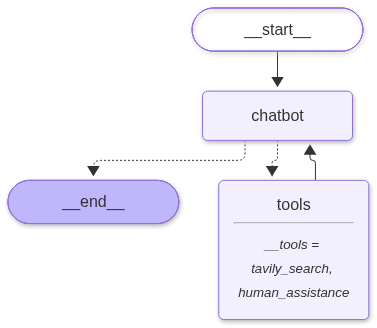

In [29]:
from IPython.display import Image, display
from langgraph.checkpoint.memory import MemorySaver
# ১. রোবটের মেমোরি ডায়েরি তৈরি করা হলো
memory = MemorySaver()
graph = graph_builder.compile(checkpointer=memory)

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    # This requires some extra dependencies and it optional
   pass

In [31]:
user_input = "I need some expert guidance  amd assistance for building an AI agent. Could you request assistance for me?"
config= {"configurable":{"thread_id":"1"}}

events = graph.stream(
    {"messages":user_input},
    config,
    stream_mode = "values",

)

for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()


================================ Human Message =================================

I need some expert guidance  amd assistance for building an AI agent. Could you request assistance for me?
================================== Ai Message ==================================

I'll request assistance from a human expert on your behalf for building an AI agent.
Tool Calls:
  human_assistance (t24m3vmy2)
 Call ID: t24m3vmy2
  Args:
    query: I need expert guidance and assistance for building an AI agent. Could you help me with best practices, architecture, tool use, memory, planning, and evaluation for building a robust AI agent?
================================== Ai Message ==================================

I'll request assistance from a human expert on your behalf for building an AI agent.
Tool Calls:
  human_assistance (t24m3vmy2)
 Call ID: t24m3vmy2
  Args:
    query: I need expert guidance and assistance for building an AI agent. Could you help me with best practices, architecture, tool

In [33]:
human_response = (
    "We, the experts are here to help! we'd recommend you to check out Langgraph to build your agent."
    "It's much more reliable and extensible than simple autonomous agents."
)

human_command = Command(resume ={"data": human_response})
events = graph.stream(human_command,config,stream_mode ="values")
for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================== Ai Message ==================================

Here's what the human expert shared with you:

> "We, the experts are here to help! We'd recommend you to check out **LangGraph** to build your agent. It's much more reliable and extensible than simple autonomous agents."

**Quick context on their recommendation:**
- **LangGraph** is a framework from the LangChain team for building stateful, multi-actor AI applications using graphs (nodes and edges).
- It's well-suited for agents because it gives you explicit control over the **execution flow**, **state management**, **loops**, and **human-in-the-loop** checkpoints — which is why it's often preferred over simpler "autonomous" agent loops for production use.

Would you like me to dig into anything specific next — for example:
1. How to structure a LangGraph agent (state, nodes, edges, tools)?
2. Comparison of agent frameworks (LangGraph vs. AutoGen vs. CrewAI vs. OpenAI Agents SDK)?
3. Best practices for t